In [45]:
# importamos librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
# cargamos archivos

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [47]:
# mostramos las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [48]:
# mostramos las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [49]:

# mostramos las primeras 5 filas de usage

usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [50]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [51]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [52]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [53]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


In [54]:

# cantidad de nulos para users
print('Cantidad de valores nulos users')
print(users.isna().sum())
print()
print('Proporción de valores nulos users')
print(users.isna().mean()*100)


Cantidad de valores nulos users
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos users
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [55]:
# cantidad de nulos para usage
print('Cantidad de valores nulos usage')
print(usage.isna().sum())
print()
print('Proporción de valores nulos usage')
print(usage.isna().mean()*100)


Cantidad de valores nulos usage
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos usage
id           0.000
user_id      0.000
type         0.000
date         0.125
duration    55.190
length      44.740
dtype: float64


Diagnóstico de valores nulos

Dataset plans:


No presenta valores nulos, por lo que no requiere tratamiento.

Dataset users:

city (11,725 %): se recomienda investigar los valores faltantes y conservarlos como nulos si no es posible recuperar la ciudad, evitando asignar ubicaciones incorrectas.

churn_date (88,35 %): aunque presenta un porcentaje elevado de nulos, podrían corresponder a clientes activos. Se recomienda conservarlos y verificar su significado antes de realizar modificaciones.

Dataset usage:

date (0,125 %): se recomienda investigar los 50 registros sin fecha y evaluar su exclusión de los análisis temporales si no es posible recuperar la información.

duration (55,19 %): se recomienda verificar si los nulos corresponden a mensajes de texto, ya que estos no tienen duración de llamada. En ese caso, se conservarían.

length (44,74 %): se recomienda verificar si los nulos corresponden a llamadas, ya que estas no tienen longitud de mensaje. En ese caso, se conservarían.

In [56]:
# exploramos columnas numéricas de users
print('Resumen estadístico de tabla users')
print()
users.describe()

Resumen estadístico de tabla users



,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` La columna user_id contiene 4.000 registros, con valores entre 10000 y 13999. No se observan valores inválidos en el resumen estadístico.

- La columna `age` presenta un valor mínimo de -999, que es inválido y podría corresponder a un sentinel. Este valor afecta la media (33,74 años), que resulta inferior a la mediana (47 años). Se recomienda identificar y tratar estos valores antes de realizar el análisis estadístico.


In [57]:

# exploramos columnas numéricas de usage
print('Resumen estadístico de tabla usage')
print()
usage
usage.describe()

Resumen estadístico de tabla usage



,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000



-Las columnas `id` y `user_id` contienen 40.000 registros sin valores nulos. id presenta valores entre 1 y 40000, mientras que user_id varía entre 10000 y 13999, dentro del rango observado en el dataset users. No se identifican valores inválidos evidentes.

-La columna `duration` presenta valores entre 0 y 120 minutos, con una media de 5,20 y una mediana de 3,50 minutos. La diferencia entre ambas sugiere la presencia de llamadas de duración elevada. Se recomienda investigar los valores extremos y verificar si las duraciones iguales a 0 son válidas.

-La columna `length` presenta valores entre 0 y 1490 caracteres, con una media de 52,13 y una mediana de 50. Se observan valores máximos considerablemente superiores al tercer cuartil (64), lo que podría indicar valores atípicos. Se recomienda investigar los valores extremos y los registros con longitud igual a 0.


In [58]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f'Valores únicos de {col}:')
    print(users[col].unique())
    print()



Valores únicos de city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']

Valores únicos de plan:
['Basico' 'Premium']




- La columna `city` presenta ciudades de México y Colombia, además de valores nulos (NaN) y el valor ?, que podría representar un sentinel utilizado para indicar información faltante. Se recomienda investigar y reemplazar ? por NaN durante la limpieza.

- La columna `plan` presenta únicamente dos categorías (Basico y Premium), que coinciden con los planes disponibles. No se observan valores inválidos ni inconsistencias.

In [59]:

# exploramos columna categórica de usage
usage['type'].unique()


array(['call', 'text'], dtype=object)

- La columna `type` presenta únicamente dos categorías (call y text), correspondientes a llamadas y mensajes de texto. No se identifican valores inválidos ni sentinels.


---
✍️ **Comentario**:

**Valores inválidos o sentinels**  


users['age']: se identificó el valor -999, que es inválido para una edad y representa un posible sentinel. Se recomienda reemplazarlo por NaN para evitar distorsiones en el análisis estadístico.

users['city']: se encontró el valor ?, que representa un posible dato faltante. Se recomienda reemplazarlo por NaN para unificar los valores ausentes.

usage['duration']: se observaron valores iguales a 0 y un máximo de 120 minutos. Se recomienda verificar su validez antes de realizar modificaciones, ya que podrían corresponder a llamadas reales.

usage['length']: se encontraron valores iguales a 0 y un máximo de 1490 caracteres. Se recomienda investigar si corresponden a registros válidos o errores antes de decidir su tratamiento.

Conclusión: Los principales posibles sentinels identificados son -999 en age y ? en city. Los valores extremos de duration y length requieren una revisión adicional, pero no deben considerarse inválidos automáticamente.

In [60]:

# Convertimos a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors = 'coerce')


In [61]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors = 'coerce')

In [62]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se observan registros correspondientes a los años 2022 (1.314), 2023 (1.316) y 2024 (1.330). Sin embargo, se identificaron 40 registros del año 2026, que están fuera del período de análisis (hasta 2024). Se recomienda considerar estas fechas como inválidas y reemplazarlas por NaT durante la limpieza, ya que no es posible determinar la fecha correcta.

In [63]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()


2024.0    39950
Name: date, dtype: int64

En `date`, los 39.950 registros con fecha corresponden al año 2024, por lo que no se identifican años fuera del período de análisis. Sin embargo, existen 50 registros con fechas nulas que deberán evaluarse durante la limpieza.

✍️ **Comentario**: 

**Fechas fuera de rango**  

users['reg_date']: se identificaron 40 registros correspondientes al año 2026, fuera del período de análisis (hasta 2024). Se recomienda reemplazar estas fechas por NaT, ya que no es posible determinar la fecha correcta y podrían distorsionar el análisis temporal.

usage['date']: los 39.950 registros con fecha corresponden al año 2024, por lo que no se identificaron años fuera de rango. Sin embargo, existen 50 valores nulos que se recomienda mantener como NaT y evaluar su exclusión de los análisis temporales.

Conclusión: Se detectaron fechas fuera de rango únicamente en reg_date. Se recomienda corregirlas durante la limpieza y conservar los registros siempre que puedan utilizarse en otros análisis.

In [64]:

# Función para reemplazar un sentinel

def reemplazar_sentinel(df, columna, sentinel, reemplazo):
    df[columna] = df[columna].replace(sentinel, reemplazo)
    return df

# Reemplazamos -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users = reemplazar_sentinel(users, 'age', -999, age_mediana)

# Verificamos cambios
users['age'].describe()





count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [65]:

# Reemplazamos ? por NA en city
users = reemplazar_sentinel(users, 'city', '?', pd.NA)

# Verificamos cambios
users['city'].value_counts(dropna=False)



Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [66]:
# Marcamos fechas futuras como NA para reg_date ()
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificamos cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()



2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

In [67]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()) * 100

type
call     0.000000
text    99.927576
Name: duration, dtype: float64

In [68]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().mean()) * 100

type
call    99.932991
text     0.000000
Name: length, dtype: float64

Diagnostico de nulos en `duration` y `length`

Los nulos dependen del tipo de actividad (type): duration está ausente en el 99.93 % de los mensajes y length en el 99.93 % de las llamadas. No hay duraciones nulas en llamadas ni longitudes nulas en mensajes. Conservaré estos nulos sin imputarlos, porque son nulos estructurales: la duración no aplica a los mensajes y la longitud del texto no aplica a las llamadas.

In [69]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({'is_text': 'sum','is_call': 'sum', 'duration': 'sum'}).reset_index()

# Observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [70]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text': 'cant_mensajes','is_call': 'cant_llamadas','duration': 'cant_minutos_llamada'})

# Observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [71]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


In [72]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [73]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

In [74]:
##Observamos 3999 valores en cant_mensajes, cant_llamadas, cant_minutos_llamada. 
user_profile.loc[
    user_profile['cant_mensajes'].isna(),
    ['user_id', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
]

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
1082,11082,NaN,NaN,NaN


Se conservaron los 4000 usuarios al combinar las tablas. Sin embargo, las métricas de uso tienen 3999 valores no nulos, ya que el usuario 11082 no tiene registros asociados en la tabla agregada de actividad. Se mantienen sus métricas como nulas, porque la ausencia de registros no permite confirmar que su consumo haya sido cero.

Resumen estadístico de uso por usuario

En los registros analizados, los usuarios presentan un promedio de 5,52 mensajes, 4,48 llamadas y 23,32 minutos de llamadas. Las medianas son de 5 mensajes, 4 llamadas y 19,78 minutos, respectivamente. La media de minutos supera a la mediana y el máximo alcanza los 155,69 minutos, lo que sugiere una distribución con valores altos que conviene explorar mediante histogramas y boxplots.

Se observan valores mínimos de cero en las tres métricas, compatibles con usuarios sin actividad registrada en alguno de los servicios. De los 4000 usuarios, 3999 tienen métricas de uso agregadas. El usuario 11082 no tiene registros asociados; sus métricas se conservan como nulas, ya que no es posible confirmar que su consumo haya sido cero.

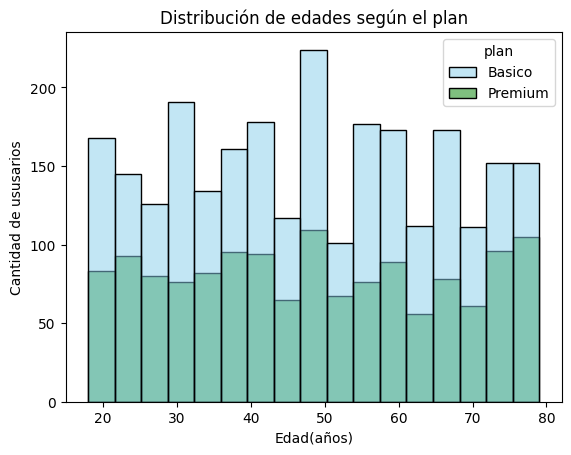

In [75]:

# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de edades según el plan')
plt.xlabel('Edad(años)')
plt.ylabel('Cantidad de ususarios')
plt.show()

💡Insights - Edad de los usuarios

Las edades presentan una distribución relativamente uniforme entre los 18 y los 79 años, sin una concentración dominante en un único rango ni un sesgo evidente hacia las edades más altas o más bajas. Los usuarios del plan Básico muestran frecuencias absolutas superiores en la mayoría de los rangos, lo que puede explicarse por su mayor presencia en la base de clientes. Visualmente, no se observa una diferencia marcada en la distribución de edades entre los dos planes.

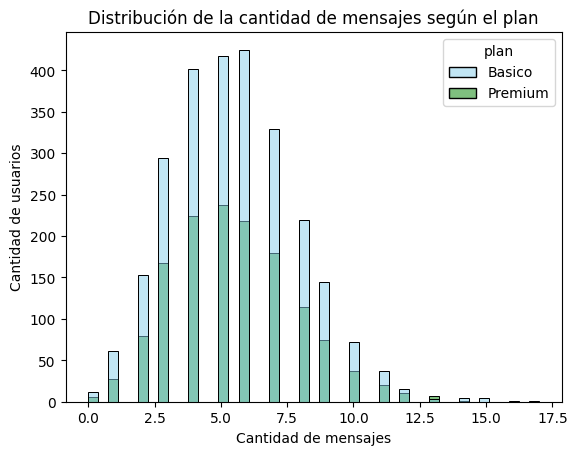

In [76]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la cantidad de mensajes según el plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights - Cantidad de mensajes

La distribución de la cantidad de mensajes se concentra principalmente entre 3 y 7 mensajes por usuario, con un pico alrededor de 5–6. Presenta un sesgo hacia la derecha, ya que la frecuencia disminuye a medida que aumenta la cantidad de mensajes. Ambos planes muestran una forma de distribución similar. El plan Básico presenta mayores frecuencias absolutas, lo que es coherente con su mayor participación en la base de clientes; por lo tanto, el gráfico no permite concluir por sí solo que sus usuarios envíen más mensajes individualmente.

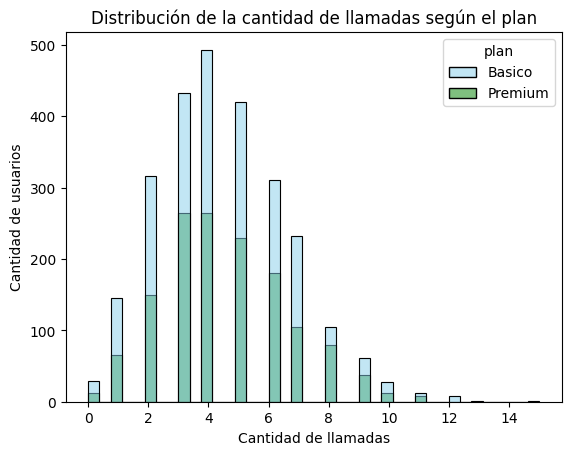

In [77]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la cantidad de llamadas según el plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights - Cantidad de llamadas

La cantidad de llamadas se concentra principalmente entre 2 y 6 por usuario, con un máximo de frecuencia alrededor de 4 llamadas. La distribución presenta un sesgo hacia la derecha, debido a que la cantidad de usuarios disminuye para frecuencias de llamadas más elevadas. Ambos planes muestran un patrón similar, aunque el plan Básico tiene mayores frecuencias absolutas. Esto no implica necesariamente que sus clientes realicen más llamadas por persona, ya que también hay más usuarios con ese plan.

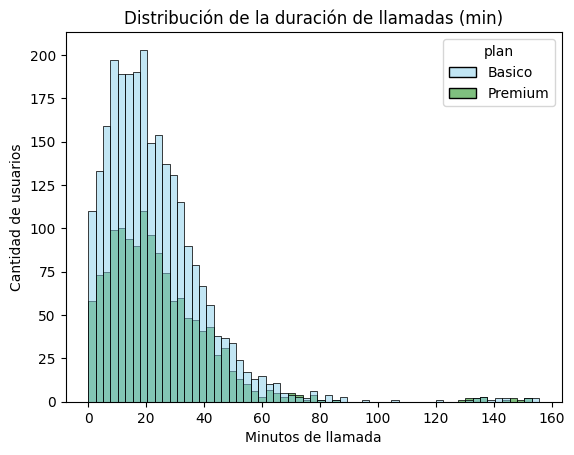

In [78]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'])
plt.title('Distribución de la duración de llamadas (min)')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights - Minutos de llamadas

La distribución de los minutos de llamadas presenta un marcado sesgo hacia la derecha. La mayoría de los usuarios registra consumos relativamente bajos o moderados, concentrados aproximadamente entre 5 y 30 minutos, mientras que una cantidad reducida alcanza valores superiores a 60 minutos. También se observan valores extremos cercanos a 150 minutos, que conviene conservar mientras no exista evidencia de que sean errores. Ambos planes presentan una forma de distribución similar. Para determinar si existen diferencias reales de consumo entre Básico y Premium, sería conveniente comparar sus medianas y promedios, considerando también el tamaño de cada grupo.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

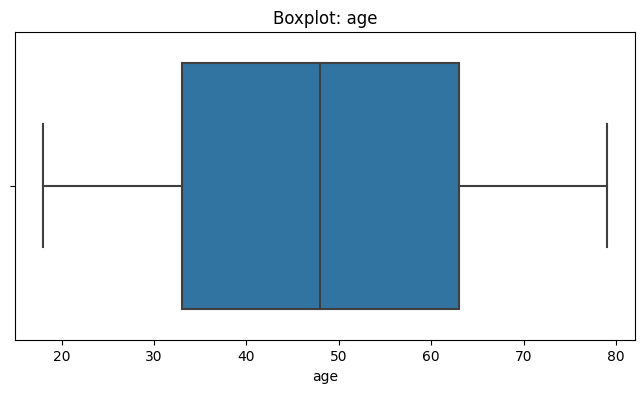

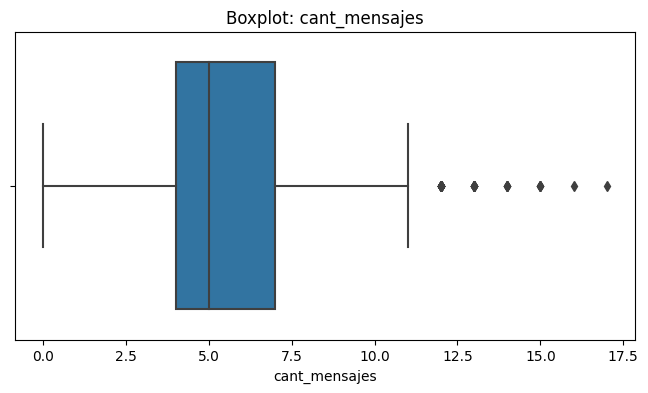

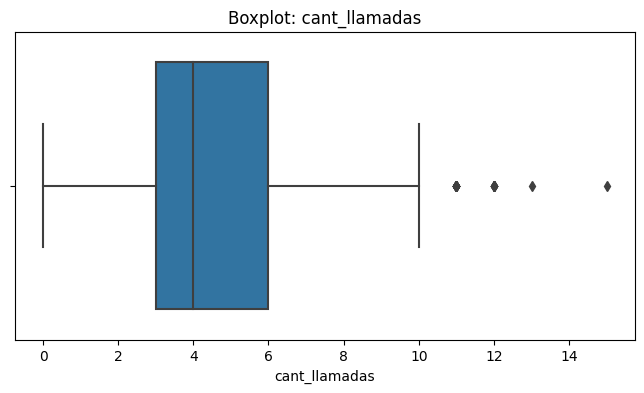

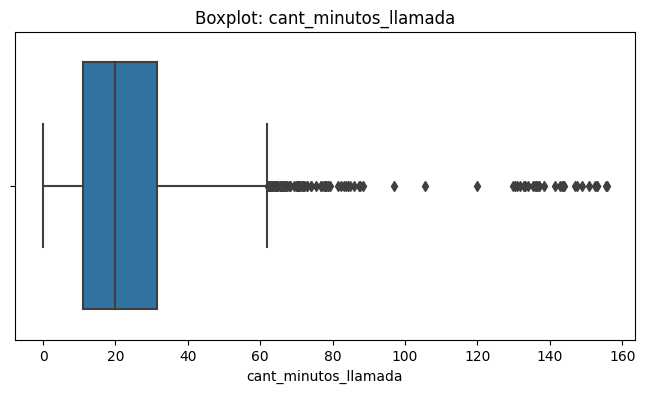

In [79]:

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()


💡 Insights:
- age: No presenta outliers según el boxplot; las edades se encuentran entre 18 y 79 años, dentro de los bigotes.
- cant_mensajes: Presenta outliers superiores, con valores de 12 a 17 mensajes. No se observan outliers inferiores.
- cant_llamadas: Presenta outliers superiores a partir de 11 llamadas, con un máximo de 15. No se observan outliers inferiores.
- cant_minutos_llamada: Presenta numerosos outliers superiores, aproximadamente por encima de 62 minutos, con un máximo de 155.69 minutos. No se observan outliers inferiores.

In [80]:

# Calcular límites con el método IQR
columnas_limites = [
    'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_superior = Q3 + 1.5 * IQR

    print(f'{col}: límite superior = {limite_superior:.2f}')


cant_mensajes: límite superior = 11.50
cant_llamadas: límite superior = 10.50
cant_minutos_llamada: límite superior = 61.86


In [81]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡 Insights:
- cant_mensajes: Mantener los outliers, porque el máximo de 17 mensajes es plausible, aunque supere el límite IQR de 11.50. No hay evidencia suficiente para considerarlos errores.
- cant_llamadas: Mantener los outliers, porque el máximo de 15 llamadas puede representar usuarios con mayor actividad, aunque supere el límite de 10.50.
- cant_minutos_llamada: Mantener los outliers, porque el máximo de 155.69 minutos puede corresponder a un consumo elevado real. Superar el límite de 61.86 minutos no justifica eliminarlos; además, son relevantes para identificar necesidades de los usuarios de alto consumo.

In [82]:
# Creamos una columna grupo_uso definiendo una funcion para aplicar condiciones

def clasificar_uso(row):
    if pd.isna(row['cant_llamadas']) or pd.isna(row['cant_mensajes']):
        return pd.NA
    elif row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'
        
user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1) 

In [83]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


In [84]:
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      778
Alto uso      278
Name: grupo_uso, dtype: int64

In [85]:
# Creamos columna grupo_edad

def clasificar_edad(row):
    if pd.isna(row['age']):
        return pd.NA
    elif row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [86]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


In [87]:
user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

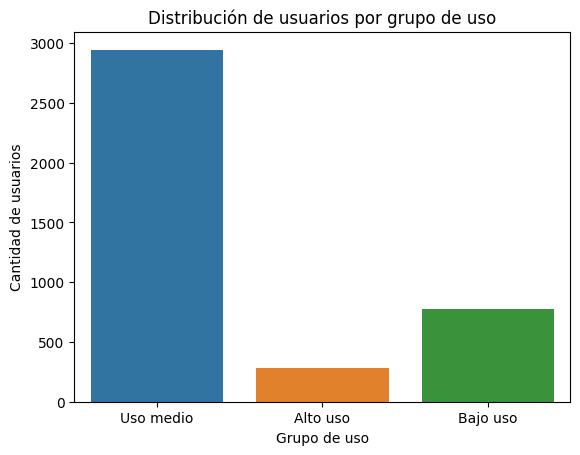

In [88]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')

plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

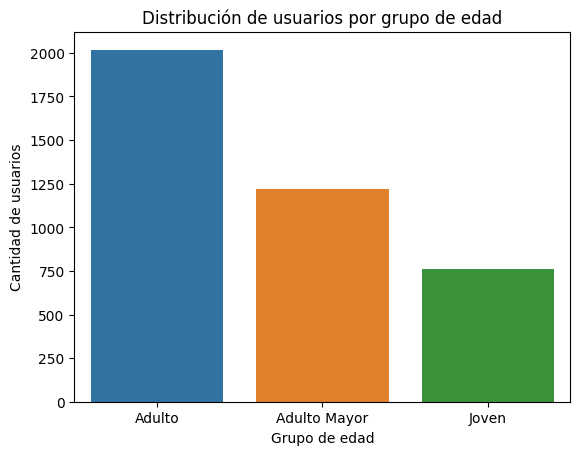

In [89]:

# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')

plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()



### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- Se corrigieron los valores inválidos de `age` y se conservaron **4000 edades no nulas**. Las **40 fechas de registro posteriores a 2024 (1 %)** se marcaron como nulas únicamente en `reg_date`, sin afectar las demás columnas. Después de reemplazar `"?"`, quedaron **565 valores nulos en `city` (14.13 %)**, incluyendo los que ya estaban ausentes.
- Se conservaron los nulos estructurales de `duration` y `length`, porque la duración no aplica a los mensajes y la longitud del texto no aplica a las llamadas.
- **Un usuario (0.025 %)** no tiene registros de uso asociados. Sus métricas se conservaron como nulas y quedó sin asignación de `grupo_uso`, evitando clasificarlo sin información suficiente.
- Se identificaron valores atípicos en las métricas de uso mediante el método IQR. Se conservaron porque podrían representar comportamientos reales y no hay evidencia suficiente para considerarlos errores.

🔍 **Segmentos por Edad**

- Entre los **4000 usuarios clasificados**, el **50.45 %** son adultos de 30 a 59 años (**2018 usuarios**), el **30.55 %** son adultos mayores de 60 años en adelante (**1222**) y el **19 %** son jóvenes menores de 30 años (**760**).
- La concentración de clientes adultos representa una oportunidad para evaluar planes ajustados a sus patrones de consumo. La presencia significativa de adultos mayores también justifica analizar sus necesidades, sin asumir que la edad por sí sola determina sus preferencias o su rentabilidad.

📊 **Segmentos por Nivel de Uso**

- De los **3999 usuarios clasificados**, el **73.59 %** presenta uso medio (**2943 usuarios**), el **19.45 %** bajo uso (**778**) y el **6.95 %** alto uso (**278**).
- El predominio del uso medio sugiere que conviene evaluar si los planes actuales se ajustan al consumo habitual de la mayoría. El segmento de bajo uso podría ser una oportunidad para investigar barreras de consumo, mientras que los usuarios de alto uso podrían beneficiarse de paquetes con mayores cantidades de llamadas y mensajes.
- Los límites superiores del método IQR fueron **11.50 mensajes, 10.50 llamadas y aproximadamente 61.86 minutos**. Los máximos observados fueron **17 mensajes, 15 llamadas y 155.69 minutos**. Estos valores permiten identificar usuarios con actividad elevada, pero no demuestran errores ni fraude.

➡️ En conjunto, los resultados permiten identificar perfiles de consumo y orientar nuevas hipótesis comerciales. Sin embargo, todavía no permiten determinar qué segmentos generan mayores ingresos, son más rentables o presentan mayor riesgo de cancelación.

💡 **Recomendaciones**

- Evaluar planes económicos o flexibles para clientes de bajo uso y paquetes de mayor capacidad para usuarios de alto uso.
- Cruzar `grupo_edad` con `grupo_uso` para identificar combinaciones de edad y consumo que permitan diseñar ofertas más específicas.
- Investigar los valores atípicos de llamadas, mensajes y minutos para distinguir consumos legítimos de posibles errores de registro.
- Comparar los segmentos con el plan contratado, los ingresos y la cancelación para priorizar las oportunidades comerciales según su impacto real.
- Comparar el consumo y los beneficios incluidos en los planes sobre un mismo período antes de recomendar cambios.
- Medir los resultados de cualquier cambio de planes mediante indicadores de consumo, ingresos por cliente y tasa de cancelación.